Dataset exists: True
Dataset path: /Users/anupamguptaroy17/Projects/VisionQC/data/raw/mvtec-ad/bottle
Normal training images: 209


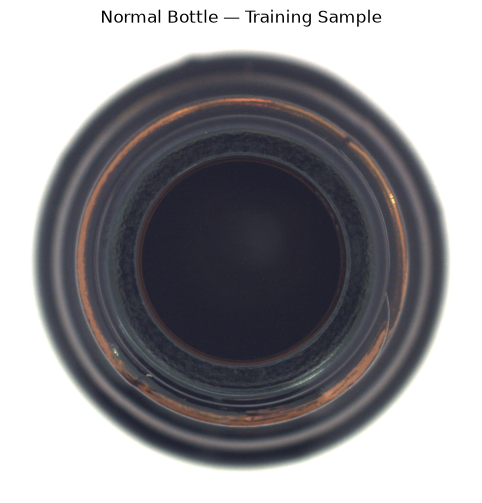

In [1]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

# Dataset location
DATA_ROOT = Path("../data/raw/mvtec-ad/bottle")

# Check the dataset path
print("Dataset exists:", DATA_ROOT.exists())
print("Dataset path:", DATA_ROOT.resolve())

# Find one normal training image
normal_images = sorted(
    (DATA_ROOT / "train" / "good").glob("*.png")
)

print("Normal training images:", len(normal_images))

# Display a sample normal bottle
image_path = normal_images[0]

with Image.open(image_path) as img:
    image = img.convert("RGB")

plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.title("Normal Bottle — Training Sample")
plt.axis("off")
plt.show()

    Display normal and defective bottles

In [2]:

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

# Dataset directory, relative to the notebooks folder
DATA_ROOT = Path("../data/raw/mvtec-ad/bottle")

# Select one normal image and one defective image
normal_path = DATA_ROOT / "train" / "good" / "000.png"
defect_path = DATA_ROOT / "test" / "broken_small" / "000.png"
mask_path = DATA_ROOT / "ground_truth" / "broken_small" / "000_mask.png"

# Check which files exist
for path in [normal_path, defect_path, mask_path]:
    print(path, "->", path.exists())


../data/raw/mvtec-ad/bottle/train/good/000.png -> True
../data/raw/mvtec-ad/bottle/test/broken_small/000.png -> True
../data/raw/mvtec-ad/bottle/ground_truth/broken_small/000_mask.png -> True


Display the defect and its mask

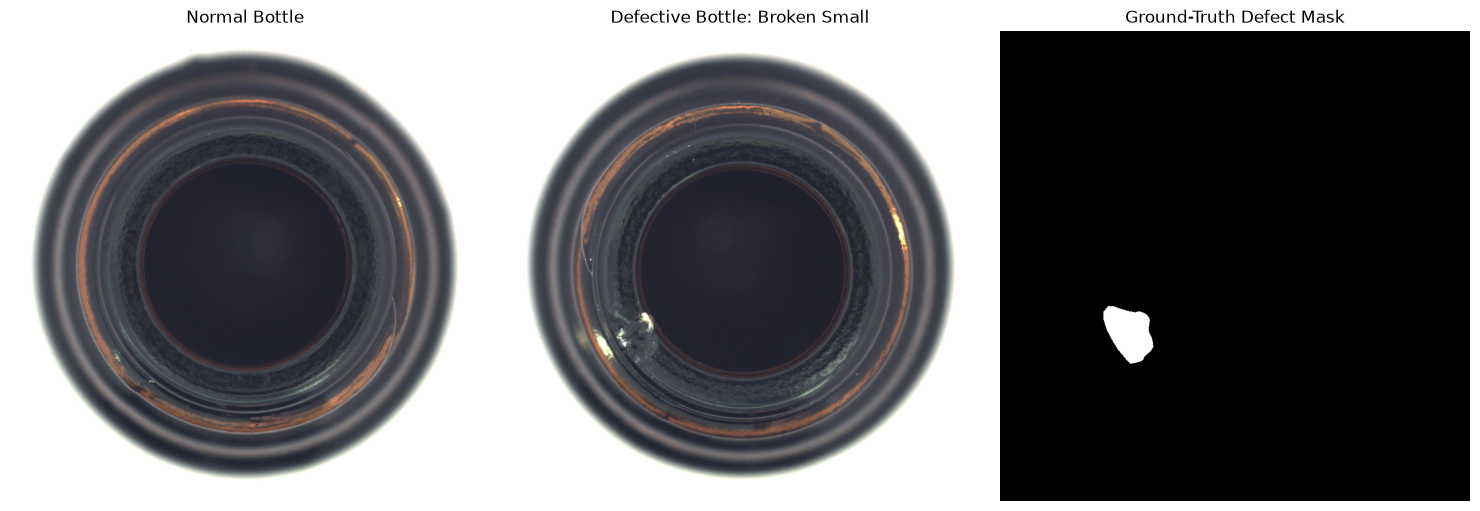

In [3]:

# Load the images
with Image.open(normal_path) as img:
    normal = img.convert("RGB")

with Image.open(defect_path) as img:
    defective = img.convert("RGB")

with Image.open(mask_path) as img:
    mask = img.convert("L")

# Visualise the normal bottle, defective bottle, and defect mask
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(normal)
axes[0].set_title("Normal Bottle")
axes[0].axis("off")

axes[1].imshow(defective)
axes[1].set_title("Defective Bottle: Broken Small")
axes[1].axis("off")

axes[2].imshow(mask, cmap="gray")
axes[2].set_title("Ground-Truth Defect Mask")
axes[2].axis("off")

plt.tight_layout()
plt.show()


Checking dataset paths

In [4]:
from pathlib import Path

DATA_ROOT = Path("../data/raw/mvtec-ad/bottle")

for split in ["train", "test", "ground_truth"]:
    folder = DATA_ROOT / split
    images = list(folder.rglob("*.png"))

    print(f"\n{split}: {len(images)} PNG files")

    for category in sorted(p.name for p in folder.iterdir() if p.is_dir()):
        count = len(list((folder / category).glob("*.png")))
        print(f"  {category}: {count}")


train: 209 PNG files
  good: 209

test: 83 PNG files
  broken_large: 20
  broken_small: 22
  contamination: 21
  good: 20

ground_truth: 63 PNG files
  broken_large: 20
  broken_small: 22
  contamination: 21


Visualising a defective bottle and its mask

Defect image exists: True
Mask exists: True


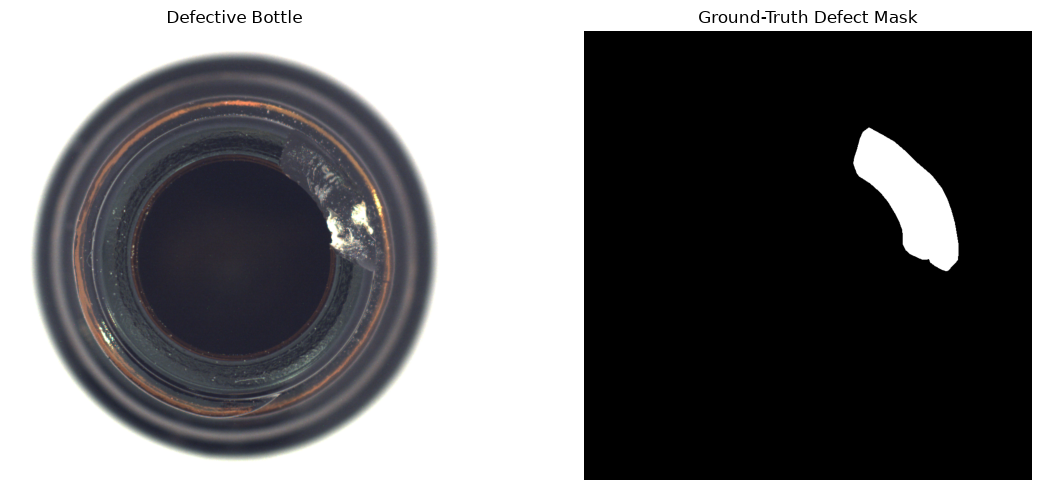

In [5]:
import matplotlib.pyplot as plt
from PIL import Image

defect_path = DATA_ROOT / "test" / "broken_small" / "002.png"
mask_path = DATA_ROOT / "ground_truth" / "broken_small" / "002_mask.png"

print("Defect image exists:", defect_path.exists())
print("Mask exists:", mask_path.exists())

if defect_path.exists() and mask_path.exists():
    with Image.open(defect_path) as img:
        defect = img.convert("RGB")

    with Image.open(mask_path) as img:
        mask = img.convert("L")

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    axes[0].imshow(defect)
    axes[0].set_title("Defective Bottle")
    axes[0].axis("off")

    axes[1].imshow(mask, cmap="gray")
    axes[1].set_title("Ground-Truth Defect Mask")
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()